In [ ]:
!nvidia-smi | head -n 8
!apt-get -qq install -y colmap ffmpeg xvfb
!git clone --recursive https://github.com/graphdeco-inria/gaussian-splatting
%cd /content/gaussian-splatting

In [ ]:
import os
os.environ["TORCH_CUDA_ARCH_LIST"] = "7.5"
!pip -q install setuptools wheel ninja plyfile tqdm
!grep -q "<cstdint>" submodules/diff-gaussian-rasterization/cuda_rasterizer/rasterizer_impl.h || sed -i '1i #include <cstdint>' submodules/diff-gaussian-rasterization/cuda_rasterizer/rasterizer_impl.h
!pip -q install --no-build-isolation submodules/diff-gaussian-rasterization submodules/simple-knn submodules/fused-ssim

In [ ]:
from google.colab import files
up = files.upload()
video = list(up.keys())[0]
!mkdir -p /content/scene/input
!ffmpeg -loglevel error -i "{video}" -vf "fps=5,scale=1280:-1" /content/scene/input/%04d.jpg
!ls /content/scene/input | wc -l

In [7]:
import os, shutil
from PIL import Image
%cd /content/gaussian-splatting
os.environ["QT_QPA_PLATFORM"] = "offscreen"

for essai in range(1, 4):
    # nettoyage complet (on garde uniquement "input")
    for d in ["distorted", "images", "sparse", "stereo"]:
        shutil.rmtree(f"/content/scene/{d}", ignore_errors=True)
    for f in ["run-colmap-geometric.sh", "run-colmap-photometric.sh"]:
        if os.path.exists(f"/content/scene/{f}"):
            os.remove(f"/content/scene/{f}")

    os.system("xvfb-run -a python convert.py -s /content/scene --no_gpu > /content/colmap.log 2>&1")

    imgs = sorted(os.listdir("/content/scene/images")) if os.path.isdir("/content/scene/images") else []
    print(f"Essai {essai} : {len(imgs)} images enregistrées")
    if len(imgs) >= 40:
        print("Taille :", Image.open("/content/scene/images/" + imgs[0]).size)
        break
else:
    print("Échec après 3 essais, envoie-moi la fin de /content/colmap.log")

/content/gaussian-splatting
Essai 1 : 56 images enregistrées
Taille : (1280, 720)


In [8]:
%cd /content/gaussian-splatting
!python train.py -s /content/scene -m /content/out --eval --iterations 7000 --test_iterations 7000 --save_iterations 7000

/content/gaussian-splatting
I0000 00:00:1794948004.647187   10472 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794948007.131941   10472 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
Optimizing /content/out
Output folder: /content/out [17/11 20:40:09]
------------LLFF HOLD------------- [17/11 20:40:09]
Reading camera 56/56 [17/11 20:40:09]
Converting point3d.bin to .ply, will happen only the first time you open the scene. [17/11 20:40:09]
Loading Training Cameras [17/11 20:40:09]
Loading Test Cameras [17/11 20:40:10]
Number of points at initialisation :  3849 [17/11 20:40:11]
Training progress: 100% 7000/7000 [04:54<00:00, 23.74it/s, Loss=0.0118844, Depth Loss=0.0000000]

[ITER 7000] Evaluating test: L1 0.0097677888614

In [9]:
!pip -q install lpips
!python render.py -m /content/out
!python metrics.py -m /content/out

from plyfile import PlyData
n = PlyData.read("/content/out/point_cloud/iteration_7000/point_cloud.ply")["vertex"].count
print("Nombre de gaussiennes :", n)

Looking for config file in /content/out/cfg_args
Config file found: /content/out/cfg_args
Rendering /content/out
Loading trained model at iteration 7000 [17/11 20:45:56]
------------LLFF HOLD------------- [17/11 20:45:56]
Reading camera 56/56 [17/11 20:45:56]
Loading Training Cameras [17/11 20:45:56]
Loading Test Cameras [17/11 20:45:57]
Rendering progress: 100% 49/49 [00:17<00:00,  2.86it/s]
Rendering progress: 100% 7/7 [00:02<00:00,  3.11it/s]

Scene: /content/out
Method: ours_7000
Metric evaluation progress:   0% 0/7 [00:00<?, ?it/s]Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth

  0% 0.00/528M [00:00<?, ?B/s]
  2% 10.5M/528M [00:00<00:04, 110MB/s]
  4% 23.8M/528M [00:00<00:04, 127MB/s]
  7% 37.0M/528M [00:00<00:03, 132MB/s]
 10% 50.9M/528M [00:00<00:03, 137MB/s]
 12% 64.0M/528M [00:00<00:03, 136MB/s]
 15% 77.0M/528M [00:00<00:03, 129MB/s]
 17% 89.5M/528M [00:00<00:03, 116MB/s]
 19% 102M/528M [00:00<00:0

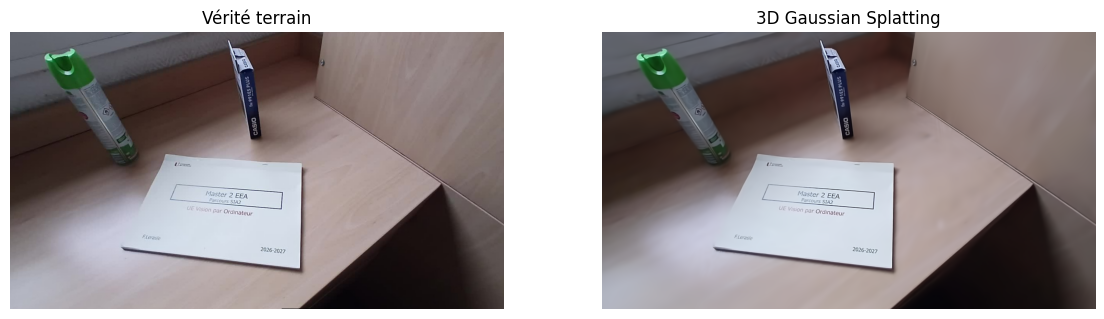

In [12]:
import os
import matplotlib.pyplot as plt
from PIL import Image

d = "/content/out/test/ours_7000"
name = sorted(os.listdir(f"{d}/renders"))[0]
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
for a, (sub, titre) in zip(ax, [("gt", "Vérité terrain"), ("renders", "3D Gaussian Splatting")]):
    a.imshow(Image.open(f"{d}/{sub}/{name}"))
    a.set_title(titre)
    a.axis("off")

plt.savefig("/content/comparaison.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
import os, shutil
from google.colab import files
from IPython.display import Video, display

base, imgs = "/content/out", "/content/scene/images"
names = sorted(f for f in os.listdir(imgs) if f.lower().endswith((".jpg", ".png")))
test_i = [i for i in range(len(names)) if i % 8 == 0]
train_i = [i for i in range(len(names)) if i % 8 != 0]

os.makedirs("/content/frames", exist_ok=True)
for split, idx in [("test", test_i), ("train", train_i)]:
    for k, i in enumerate(idx):
        shutil.copy(f"{base}/{split}/ours_7000/renders/{k:05d}.png", f"/content/frames/{i:05d}.png")

!ffmpeg -y -loglevel error -framerate 5 -i /content/frames/%05d.png -c:v libx264 -pix_fmt yuv420p /content/rendu_3dgs.mp4
display(Video("/content/rendu_3dgs.mp4", embed=True))
files.download("/content/rendu_3dgs.mp4")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>